# 13 — The executive corrections: every book funded the same way, the dependence dial, and a stronger baseline for the language model

This notebook answers the three computational requests of the executive review of 23 October 2026 (`docs/v2_review.md`) with what notebooks 01–12 built: it scores every decision process under one funding rule with the construction line priced (report v10 priced the line for book D alone), it dials the candidates' co-movement from independent to perfect and scores the books in seven worlds, and it adds the optimizer-first rule as a fifth arm beside the registered four-arm ladder. Everything here is post-registration and labelled so; no registered line is re-scored.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `data/interim/scenario_state.npz`, `results/candidate_npv.csv` | the engines of notebook 11 (primary and held-out scenarios) |
| in | `results/v8/frontier.csv`, `results/v8/process_comparison.csv`, `results/v8/statuses.csv`, `results/v8/explanations.csv` | books A–D and F as chosen in notebook 11; each candidate's status |
| in | `results/v10/cases_v10.json`, `results/v10/x1_outputs.jsonl` | the registered v10 cases and the recorded challenger outputs (read, never re-run) |
| out | `results/v2/books_financed.csv`, `books_financed_pairs.csv` | every book under the same funding rule, gross and net of the line's cost; paired intervals |
| out | `results/v2/dependence_dial.csv`, `books_worlds.csv` | the books as the co-movement is dialled and in seven worlds |
| out | `results/v2/ladder_five_arms.csv`, `ladder_five_rungs.csv` | the registered ladder with the optimizer-first rule as a fifth arm |
| out | `results/v2/book_D_members.csv`, `emissions_cap.csv`, `readiness_matrix.csv`, `checks.csv` | the recommended allocation line by line; the book under an emissions cap; the control matrix; this notebook's checks |
| out | `figures/F51_true_economics.*`, `F52_what_can_go_wrong.*`, `F53_ladder_five_arms.*`, `F54_allocation.*`, `F55_committee_workflow.*`, `F56_readiness_matrix.*` | the V2 figures |

In [1]:
import json
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import challenge as ch, challenge_experiments as cx, challenge_v10 as c10, config, optimizer as opt, paths, plots, robustness as rb, whatif as wi

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "13_executive_corrections"
START = time.time()
R = paths.RESULTS
V2 = R / "v2"
V2.mkdir(exist_ok=True)
LEVEL, LAM, CAP, SEED, N_BOOT = 0.95, 1.0, 0.40, 2020, 1000
SOURCES = [config.SOURCE_BSEE, config.SOURCE_ERCOT]
COHORT = "the forty candidates public on 1 January 2025; 2,000 held-out scenarios"
TECH_COLOR = {"Lease redevelopment": "#D55E00", "Gas CC": config.TECH_COLORS["Gas"], "Solar": config.TECH_COLORS["Solar"], "Wind": config.TECH_COLORS["Wind"], "Storage": config.TECH_COLORS["Battery"]}
BOOK_COLOR = {"A": "#999999", "B": "#CC79A7", "C": "#56B4E9", "D": "#0072B2", "F": "#009E73", "D_L": "#E69F00"}
BOOK_NAME = {"A": "A NPV ranking", "B": "B equal capital", "C": "C deterministic", "D": "D risk-aware", "F": "F lookup forecasts", "D_L": "D re-solved with the line"}

sel = wi.Engine(2000, "primary")
held = wi.Engine(2000, "held-out")
s = ch.Setting(sel, held, "committee")
x_D = np.asarray(s.x_model, int)
lease = np.ones(len(s.ids), bool)
lease[s.power_idx] = False
frontier = pd.read_csv(R / "v8" / "frontier.csv")
books = {row["policy"][0]: s.vector(row["members"].split(";")) for _, row in frontier[frontier["kind"] == "comparator"].iterrows()}
pc = pd.read_csv(R / "v8" / "process_comparison.csv").set_index("process")
books["F"] = s.vector(pc.loc["F D with naive (lookup) forecasts", "members"].split(";"))
assert np.array_equal(books["D"], x_D)
print(f"books: " + ", ".join(f"{k} {int(x.sum())} members" for k, x in books.items()) + f"; budget ${s.budget / 1e9:.2f}B; {time.time() - START:.0f} s")

books: A 15 members, B 18 members, C 17 members, D 13 members, F 20 members; budget $3.82B; 38 s


## 1. Every decision process under the same funding rule

Report v10 compared the five decision processes on a static basis — every request that reaches its agreement is built, whatever it calls for — and then priced a contingent construction line for the risk-aware book alone (notebook 12, section 2). The executive review asked the obvious question: are NPV ranking, equal capital, the deterministic optimizer and the lookup book given the same treatment? They were not. This section gives every book the same three bases: *static* (unlimited capital, as Table 2 of report v10); *no line* (construction calls beyond the book's own reserve cannot be met, so the requests that reach their agreement forfeit their deposits, `robustness.funding_or_forfeit`); and *its own line* — a facility sized at the 95th percentile of the book's own excess calls, net of the registered 0.5% commitment fee and 8% interest (`robustness.financing_cost`, decision #104). A fourth basis gives every book the same $2.53B facility book D needs, so that no book is favoured by the size of its line. The funding order within a book is fixed in advance (expected NPV per dollar of capital on the selection scenarios), the rule notebook 12 uses, so no book sees the future. Capital is split into what is spent on the day (lease capital, request deposits), what is reserved for construction (the expected draw), and what is contingent (the facility).

In [2]:
def power_value(x, line, fee, rate, A=None, op_year=None):
    # a book's held-out power value under the funding rule, net of the line's cost; the lease side is unaffected by the line
    A = s.A_h if A is None else A
    op_year = held.op_year if op_year is None else op_year
    reserve = float((s.capex_p * s.p7)[x[s.power_idx] == 1].sum())
    return rb.funding_or_forfeit(A[:, s.power_idx], op_year, s.capex_p, s.carry_p, x[s.power_idx], reserve, line, s.priority, fee=fee, rate=rate)


def totals_of(x, line, fee=0.0, rate=0.0):
    return s.A_h[:, lease] @ x[lease] + power_value(x, line, fee, rate)


def scores_of(t):
    return {"mean": float(t.mean()), "cvar_loss": float(opt.cvar(-t, LEVEL)), "metric": float(t.mean() - LAM * opt.cvar(-t, LEVEL)), "p_loss": float((t < 0).mean())}


LINE_D = float(rb.capital_calls(held.op_year, s.capex_p, x_D[s.power_idx], s.p7)["excess_q95"])  # the facility book D needs (notebook 12)
rows, totals = [], {}
for name, x in books.items():
    xp = x[s.power_idx]
    calls = rb.capital_calls(held.op_year, s.capex_p, xp, s.p7)
    deposits = float((s.carry_p * xp).sum())
    lease_capital = float((s.charge * x)[lease].sum())
    bases = {"static (unlimited capital)": totals_of(x, 1e12), "no line (calls beyond the reserve forfeit)": totals_of(x, 0.0),
             "own line, gross": totals_of(x, calls["excess_q95"]), "own line, net of fee and interest": totals_of(x, calls["excess_q95"], config.LINE_FEE, config.LINE_RATE),
             "common $2.53B line, net of fee and interest": totals_of(x, LINE_D, config.LINE_FEE, config.LINE_RATE)}
    totals[name] = bases
    financing = float(bases["own line, gross"].mean() - bases["own line, net of fee and interest"].mean())
    for basis, t in bases.items():
        rows.append({"book": name, "name": BOOK_NAME[name], "basis": basis, "members": int(x.sum()), "leases": int(x[lease].sum()), "requests": int(xp.sum()),
                     "capital_committed": float(s.charge @ x), "lease_capital": lease_capital, "deposits": deposits, "reserve": calls["reserve"],
                     "facility_own_q95": calls["excess_q95"], "p_calls_over_reserve": calls["p_over"], "financing_cost_mean_own_line": financing, **scores_of(t)})
financed = pd.DataFrame(rows)
financed.to_csv(V2 / "books_financed.csv", index=False)
view = financed.pivot(index="book", columns="basis", values="metric").reindex(list(books)) / 1e9
view = view[["static (unlimited capital)", "no line (calls beyond the reserve forfeit)", "own line, gross", "own line, net of fee and interest", "common $2.53B line, net of fee and interest"]]
lead = {basis: view[basis].idxmax() for basis in view.columns}
print("the book that scores best on the registered metric, by basis: " + "; ".join(f"{b}: {lead[b]}" for b in view.columns))
print(f"book D's facility ${LINE_D / 1e9:.2f}B; {time.time() - START:.0f} s")
view.round(3)

the book that scores best on the registered metric, by basis: static (unlimited capital): D; no line (calls beyond the reserve forfeit): B; own line, gross: D; own line, net of fee and interest: D; common $2.53B line, net of fee and interest: D
book D's facility $2.53B; 39 s


basis,static (unlimited capital),no line (calls beyond the reserve forfeit),"own line, gross","own line, net of fee and interest","common $2.53B line, net of fee and interest"
book,,,,,
A,1.129,0.680,1.016,0.722,0.720
B,1.109,0.867,1.015,0.711,0.788
C,1.212,0.763,1.111,0.820,0.797
D,1.348,0.757,1.268,1.034,1.034
F,1.311,0.771,1.255,0.964,0.975


In [3]:
cap_view = financed[financed["basis"] == "own line, net of fee and interest"].set_index("book")[["members", "leases", "requests", "capital_committed", "lease_capital", "deposits", "reserve", "facility_own_q95", "p_calls_over_reserve", "financing_cost_mean_own_line"]]
(cap_view.assign(**{c: cap_view[c] / 1e9 for c in ("capital_committed", "lease_capital", "deposits", "reserve", "facility_own_q95")}, financing_cost_mean_own_line=cap_view["financing_cost_mean_own_line"] / 1e6)).round(3)

,members,leases,requests,capital_committed,lease_capital,deposits,reserve,facility_own_q95,p_calls_over_reserve,financing_cost_mean_own_line
book,,,,,,,,,,
A,15,4,11,3.812,1.453,0.008,2.351,2.507,0.460,130.531
B,18,8,10,3.421,1.520,0.009,1.892,2.911,0.450,142.688
C,17,8,9,3.811,1.520,0.007,2.284,2.455,0.450,129.146
D,13,5,8,3.778,1.417,0.007,2.354,2.529,0.503,126.243
F,20,8,12,3.748,1.520,0.011,2.218,3.152,0.482,147.179


Paired intervals on the financed basis: the risk-aware book against each conventional book, every book funded within its own line net of the fee and the interest, by resampling held-out scenarios (the rule C33 used, `optimizer.paired_scenario_bootstrap`, applied to the funded totals). A second check re-solves the risk-aware book with book D's $2.53B facility as an explicit constraint — the CVaR of construction calls beyond the reserve must fit within the line (`challenge.liquidity`, the same constraint the challenger's repair uses) — to see whether the recommended book changes when the line is part of the choice rather than priced after it.

In [4]:
def paired(t_a, t_b, n_boot=N_BOOT, seed=SEED):
    # interval of metric(a) - metric(b) by resampling scenarios with replacement, the C33 rule on funded totals
    rng = np.random.default_rng(seed)
    S = len(t_a)
    diffs = np.empty(n_boot)
    for k in range(n_boot):
        idx = rng.integers(0, S, size=S)
        a, b = t_a[idx], t_b[idx]
        diffs[k] = (a.mean() - LAM * opt.cvar(-a, LEVEL)) - (b.mean() - LAM * opt.cvar(-b, LEVEL))
    point = (t_a.mean() - LAM * opt.cvar(-t_a, LEVEL)) - (t_b.mean() - LAM * opt.cvar(-t_b, LEVEL))
    return {"diff": float(point), "low": float(np.quantile(diffs, 0.025)), "high": float(np.quantile(diffs, 0.975))}


# the risk-aware book re-solved with the $2.53B facility as a constraint (post-registration, labelled)
d_l = opt.solve_milp(s.A, s.charge, s.budget, lam=LAM, level=LEVEL, groups=s.tech, group_cap=CAP, calls=s.calls, calls_cap=LINE_D)
x_DL = np.asarray(d_l["x"], int)
books["D_L"] = x_DL
calls_DL = rb.capital_calls(held.op_year, s.capex_p, x_DL[s.power_idx], s.p7)
t_DL = {"own line, net of fee and interest": totals_of(x_DL, calls_DL["excess_q95"], config.LINE_FEE, config.LINE_RATE),
        "common $2.53B line, net of fee and interest": totals_of(x_DL, LINE_D, config.LINE_FEE, config.LINE_RATE), "static (unlimited capital)": totals_of(x_DL, 1e12)}
totals["D_L"] = t_DL
for basis, t in t_DL.items():
    financed = pd.concat([financed, pd.DataFrame([{"book": "D_L", "name": BOOK_NAME["D_L"], "basis": basis, "members": int(x_DL.sum()), "leases": int(x_DL[lease].sum()), "requests": int(x_DL[s.power_idx].sum()),
                                                   "capital_committed": float(s.charge @ x_DL), "facility_own_q95": calls_DL["excess_q95"], "p_calls_over_reserve": calls_DL["p_over"], **scores_of(t)}])], ignore_index=True)
financed.to_csv(V2 / "books_financed.csv", index=False)
pairs = []
for basis in ("static (unlimited capital)", "own line, net of fee and interest", "common $2.53B line, net of fee and interest"):
    for other in ("A", "B", "C", "F"):
        pairs.append({"basis": basis, "book": "D", "against": other, **paired(totals["D"][basis], totals[other][basis])})
    pairs.append({"basis": basis, "book": "D_L", "against": "D", **paired(totals["D_L"][basis], totals["D"][basis])})
pairs = pd.DataFrame(pairs)
pairs.to_csv(V2 / "books_financed_pairs.csv", index=False)
same = int((x_DL == x_D).all())
print(f"D re-solved with the line as a constraint: {int(x_DL.sum())} members, Jaccard to D {opt.jaccard(x_DL, x_D):.2f}, identical to D: {bool(same)}; its own facility ${calls_DL['excess_q95'] / 1e9:.2f}B; {time.time() - START:.0f} s")
(pairs.assign(**{c: pairs[c] / 1e6 for c in ("diff", "low", "high")})).round(0)

D re-solved with the line as a constraint: 9 members, Jaccard to D 0.69, identical to D: False; its own facility $1.31B; 50 s


,basis,book,against,diff,low,high
0,static (unlimited capital),D,A,219.0,18.0,400.0
1,static (unlimited capital),D,B,239.0,47.0,437.0
2,static (unlimited capital),D,C,136.0,-59.0,322.0
3,static (unlimited capital),D,F,37.0,-73.0,154.0
4,static (unlimited capital),D_L,D,-163.0,-229.0,-91.0
5,"own line, net of fee and interest",D,A,312.0,110.0,506.0
6,"own line, net of fee and interest",D,B,323.0,127.0,532.0
7,"own line, net of fee and interest",D,C,213.0,17.0,412.0
8,"own line, net of fee and interest",D,F,70.0,-51.0,201.0
9,"own line, net of fee and interest",D_L,D,-49.0,-127.0,23.0


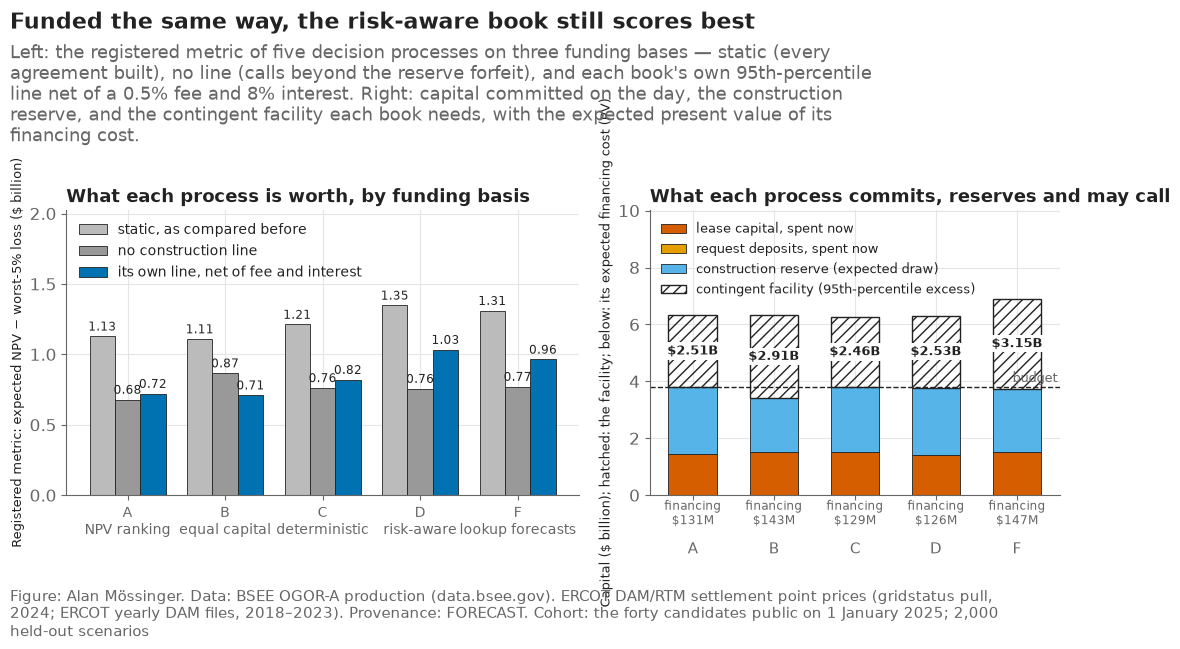

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1.25, 1]})
order = ["A", "B", "C", "D", "F"]
bases = [("static (unlimited capital)", "static, as compared before", "#BBBBBB"), ("no line (calls beyond the reserve forfeit)", "no construction line", "#999999"),
         ("own line, net of fee and interest", "its own line, net of fee and interest", "#0072B2")]
width = 0.26
for j, (basis, label, color) in enumerate(bases):
    vals = [financed[(financed["book"] == b) & (financed["basis"] == basis)]["metric"].iloc[0] / 1e9 for b in order]
    axes[0].bar(np.arange(len(order)) + (j - 1) * width, vals, width, color=color, label=label, edgecolor=plots.INK, linewidth=0.6)
    for i, v in enumerate(vals):
        axes[0].text(i + (j - 1) * width, v + 0.02, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5, color=plots.INK)
axes[0].set_xticks(np.arange(len(order)), [BOOK_NAME[b].replace(" ", chr(10), 1) for b in order], fontsize=10)
axes[0].set_ylabel("Registered metric: expected NPV − worst-5% loss ($ billion)")
axes[0].legend(loc="upper left", fontsize=10, frameon=False)
axes[0].set_ylim(0, max(financed["metric"]) / 1e9 * 1.5)
axes[0].set_title("What each process is worth, by funding basis", fontsize=13)
own = financed[financed["basis"] == "own line, net of fee and interest"].set_index("book").reindex(order)
bottom = np.zeros(len(order))
for col, label, color in (("lease_capital", "lease capital, spent now", "#D55E00"), ("deposits", "request deposits, spent now", "#E69F00"), ("reserve", "construction reserve (expected draw)", "#56B4E9")):
    v = own[col].to_numpy() / 1e9
    axes[1].bar(np.arange(len(order)), v, 0.6, bottom=bottom, color=color, label=label, edgecolor=plots.INK, linewidth=0.6)
    bottom += v
fac = own["facility_own_q95"].to_numpy() / 1e9
axes[1].bar(np.arange(len(order)), fac, 0.6, bottom=bottom, color="none", edgecolor=plots.INK, hatch="///", linewidth=1.0, label="contingent facility (95th-percentile excess)")
for i, (b, f, c) in enumerate(zip(order, fac, own["financing_cost_mean_own_line"].to_numpy() / 1e6)):
    axes[1].text(i, bottom[i] + f / 2, f"${f:.2f}B", ha="center", va="center", fontsize=9.5, color=plots.INK, fontweight="bold", bbox=dict(facecolor="white", edgecolor="none", pad=1.5))
    axes[1].text(i, -0.12, f"financing\n${c:.0f}M", ha="center", va="top", fontsize=8.5, color=plots.MUTED)
axes[1].axhline(s.budget / 1e9, color=plots.INK, lw=1, ls="--")
axes[1].text(len(order) - 0.5, s.budget / 1e9 + 0.05, "budget", ha="right", va="bottom", fontsize=9.5, color=plots.MUTED)
axes[1].set_xticks(np.arange(len(order)), [b for b in order], fontsize=11)
axes[1].tick_params(axis="x", pad=30)
axes[1].set_ylabel("Capital ($ billion); hatched: the facility; below: its expected financing cost (PV)")
axes[1].set_ylim(0, (bottom + fac).max() * 1.45)
axes[1].legend(loc="upper left", fontsize=9, frameon=False)
axes[1].set_title("What each process commits, reserves and may call", fontsize=13)
leader = lead["own line, net of fee and interest"]
title = (f"Funded the same way, the risk-aware book still scores best" if leader == "D" else f"Funded the same way, book {leader} scores best, not the risk-aware one")
plots.finish(fig, title,
             "Left: the registered metric of five decision processes on three funding bases — static (every agreement built), no line (calls beyond the reserve forfeit), and each book's own 95th-percentile line net of a 0.5% fee and 8% interest. Right: capital committed on the day, the construction reserve, and the contingent facility each book needs, with the expected present value of its financing cost.",
             COHORT, lbnl=False, sources=SOURCES, provenance="FORECAST")
plots.save_fig(fig, "F51_true_economics", "The true economics of capital allocation: every decision process on the same funding basis, before and after the construction line is priced, with the capital each commits, reserves and may call.", NOTEBOOK)
plt.show()

**Reading this.** Report v10's Table 2 compared the five processes on the static basis — every request that reaches its agreement is built — and priced the construction line for book D alone. On the same funded basis, each book within its own 95th-percentile line net of the 0.5% fee and 8% interest, the risk-aware book scores $1.03B on the registered metric against $0.82B for the deterministic optimizer, $0.72B for NPV ranking, $0.71B for equal capital and $0.96B for the lookup book. Its margin over NPV ranking widens from +$219M on the static basis to +$312M [+$110M, +$506M], and it now beats the deterministic book clear of zero (+$213M [+$17M, +$412M]) where the static comparison did not; against the lookup book the interval still includes zero (+$70M [−$51M, +$201M]). A common $2.53B line gives the same order. Two things the static table hid. First, with no line at all equal capital scores best ($0.87B against $0.76B for D): the recommendation depends on the facility. Second, every process needs one — $2.46B to $3.15B at its own 95th percentile, called beyond the reserve in 45% to 50% of scenarios — and financing costs each of them $126M to $147M in expected present value, so no book is favoured by the line. The capital a committee commits on the day is $3.42B to $3.81B of the $3.82B budget, almost all of it lease capital and construction reserve; the deposits are a few million. The re-solved book, with the $2.53B line as a hard constraint on the CVaR of calls, holds 9 members, needs a $1.31B facility and scores −$49M [−$127M, +$23M] against D on the financed basis: pricing the line after the choice loses nothing, and the recommended book stands.

## 2. What can go wrong: the co-movement dial and seven worlds

Report v10 found that removing the candidates' co-movement cuts book D's worst-5% loss from $0.82B to $0.02B (notebook 12, section 4). The review asked what that means: a real concentration of risk, or a result that hangs on the dependence model? This section dials the co-movement rather than switching it off. For a share ω of the scenario rows each candidate's column keeps its joint alignment and the rest is shuffled: ω = 0 is independence (the ablation), ω = 1 the joint scenarios as scored, and between them the tail grows as the co-movement is restored. A comonotonic bound — every column sorted, so every candidate has its worst scenario on the same day — marks the heaviest tail any dependence structure could give these marginals. Then every book is scored, on the static basis, in seven worlds: the base model, ERCOT prices 25% lower, ERCOT half as volatile, lease capital 30% higher, every plant two years late, completion as the lookup says, and WTI at $45 for five years (the stresses of notebooks 11 and 12 on one table).

In [6]:
rng = np.random.default_rng(SEED)
S_, n_ = s.A_h.shape
dial_rows = []
OMEGAS = (0.0, 0.25, 0.5, 0.75, 1.0)
matrices = {}
for omega in OMEGAS:
    A_w = s.A_h.copy()
    keep = rng.random(S_) < omega  # the rows that keep their joint alignment
    free = np.where(~keep)[0]
    for j in range(n_):
        A_w[free, j] = A_w[rng.permutation(free), j]  # the rest shuffled within themselves: every candidate's own distribution is kept
    matrices[f"omega {omega:g}"] = A_w
A_co = np.sort(s.A_h, axis=0)  # comonotonic: every candidate's k-th worst value on the same row
matrices["comonotonic bound"] = A_co
for label, A_w in matrices.items():
    for name in ("A", "B", "C", "D", "F"):
        t = A_w @ books[name]
        dial_rows.append({"dependence": label, "omega": float(label.split()[1]) if label.startswith("omega") else np.nan, "book": name, **scores_of(t)})
dial = pd.DataFrame(dial_rows)
dial.to_csv(V2 / "dependence_dial.csv", index=False)
dD = dial[dial["book"] == "D"].set_index("dependence")
print("book D's worst-5% loss as the co-movement is dialled: " + "; ".join(f"{k} ${v / 1e9:.2f}B" for k, v in dD["cvar_loss"].items()) + f"; {time.time() - START:.0f} s")
(dial.pivot(index="dependence", columns="book", values="cvar_loss").reindex(list(matrices)) / 1e9).round(3)

book D's worst-5% loss as the co-movement is dialled: omega 0 $-0.03B; omega 0.25 $0.20B; omega 0.5 $0.53B; omega 0.75 $0.69B; omega 1 $0.82B; comonotonic bound $2.19B; 53 s


book,A,B,C,D,F
dependence,,,,,
omega 0,0.467,0.282,0.213,-0.027,-0.038
omega 0.25,0.838,0.682,0.725,0.202,0.327
omega 0.5,1.164,0.949,1.054,0.534,0.706
omega 0.75,1.424,1.254,1.384,0.690,0.922
omega 1,1.550,1.329,1.518,0.822,1.089
comonotonic bound,3.658,3.254,3.425,2.186,2.754


In [7]:
world_set = cx.worlds(s)  # base, ERCOT -25%, ERCOT half as volatile, lease capital +30%, completion as the lookup says
world_set["every plant two years late"] = (ch.held_matrix(s, wi.WhatIf(grid="committee", delay_years=2)), held.op_year)
world_set["WTI at $45 for five years"] = (ch.held_matrix(s, wi.WhatIf(grid="committee", wti_level=45.0)), held.op_year)
WORLD_ORDER = ["base model", "ERCOT prices 25% lower", "ERCOT half as volatile", "lease capital 30% higher", "every plant two years late", "completion as the lookup says", "WTI at $45 for five years"]
wrows = []
for world in WORLD_ORDER:
    A_w, _ = world_set[world]
    for name in ("A", "B", "C", "D", "F"):
        wrows.append({"world": world, "book": name, **scores_of(A_w @ books[name])})
worlds_tab = pd.DataFrame(wrows)
worlds_tab.to_csv(V2 / "books_worlds.csv", index=False)
best_by_world = worlds_tab.loc[worlds_tab.groupby("world")["metric"].idxmax()].set_index("world")["book"].reindex(WORLD_ORDER)
print("the book that scores best on the registered metric, by world: " + "; ".join(f"{w}: {b}" for w, b in best_by_world.items()) + f"; {time.time() - START:.0f} s")
(worlds_tab.pivot(index="world", columns="book", values="metric").reindex(WORLD_ORDER) / 1e9).round(3)

the book that scores best on the registered metric, by world: base model: D; ERCOT prices 25% lower: D; ERCOT half as volatile: D; lease capital 30% higher: D; every plant two years late: D; completion as the lookup says: D; WTI at $45 for five years: D; 147 s


book,A,B,C,D,F
world,,,,,
base model,1.129,1.109,1.212,1.348,1.311
ERCOT prices 25% lower,-0.840,-0.425,-0.749,0.544,0.019
ERCOT half as volatile,0.314,0.548,0.403,0.896,0.715
lease capital 30% higher,0.138,0.075,0.187,0.360,0.267
every plant two years late,0.966,0.959,1.033,1.200,1.153
completion as the lookup says,2.330,2.412,2.674,2.741,2.682
WTI at $45 for five years,-0.061,-0.142,-0.026,0.223,0.103


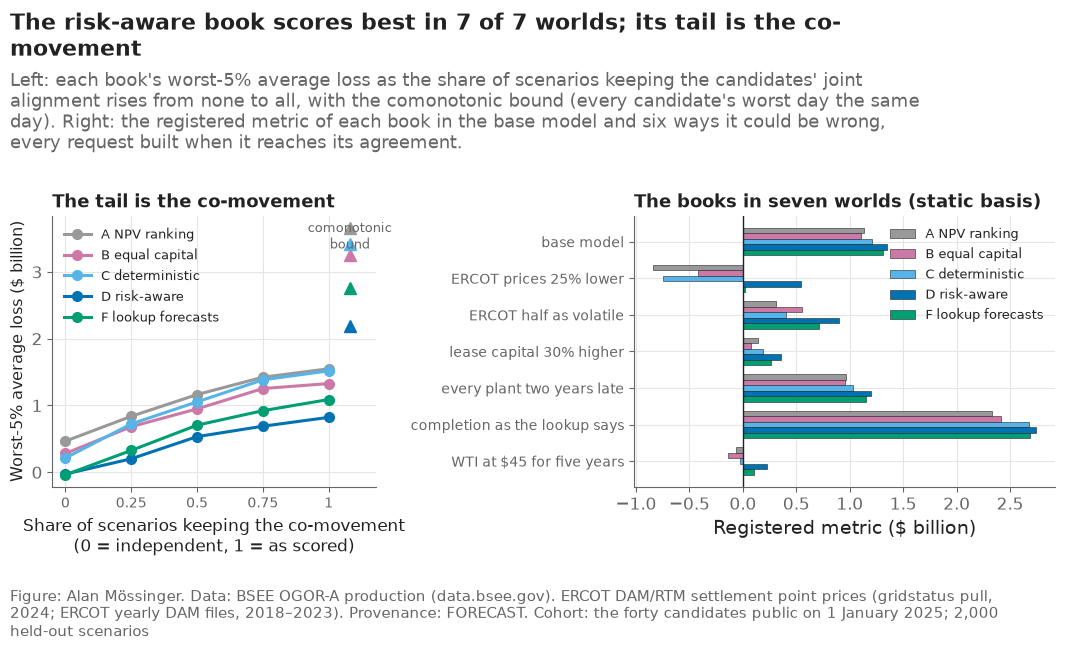

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1, 1.3]})
for name in ("A", "B", "C", "D", "F"):
    d = dial[(dial["book"] == name) & dial["omega"].notna()].sort_values("omega")
    axes[0].plot(d["omega"], d["cvar_loss"] / 1e9, marker="o", lw=2.2, ms=7, color=BOOK_COLOR[name], label=BOOK_NAME[name])
    co = dial[(dial["book"] == name) & (dial["dependence"] == "comonotonic bound")]["cvar_loss"].iloc[0] / 1e9
    axes[0].plot([1.08], [co], marker="^", ms=9, color=BOOK_COLOR[name], ls="none")
axes[0].text(1.08, axes[0].get_ylim()[1] * 0.98, "comonotonic\nbound", ha="center", va="top", fontsize=9, color=plots.MUTED)
axes[0].set_xticks(list(OMEGAS), ["0", "0.25", "0.5", "0.75", "1"], fontsize=10)
axes[0].set_xlim(-0.05, 1.18)
axes[0].set_xlabel("Share of scenarios keeping the co-movement\n(0 = independent, 1 = as scored)", fontsize=12)
axes[0].set_ylabel("Worst-5% average loss ($ billion)")
axes[0].legend(fontsize=9.5, frameon=False, loc="upper left")
axes[0].set_title("The tail is the co-movement", fontsize=13)
wv = worlds_tab.pivot(index="world", columns="book", values="metric").reindex(WORLD_ORDER) / 1e9
y = np.arange(len(WORLD_ORDER))
h = 0.15
for j, name in enumerate(("A", "B", "C", "D", "F")):
    axes[1].barh(y + (j - 2) * h, wv[name], h, color=BOOK_COLOR[name], label=BOOK_NAME[name], edgecolor=plots.INK, linewidth=0.4)
axes[1].axvline(0, color=plots.INK, lw=1)
axes[1].set_yticks(y, WORLD_ORDER, fontsize=10)
axes[1].invert_yaxis()
axes[1].set_xlabel("Registered metric ($ billion)")
axes[1].legend(fontsize=9, frameon=False, loc="upper right")
axes[1].set_title("The books in seven worlds (static basis)", fontsize=13)
n_best_D = int((best_by_world == "D").sum())
plots.finish(fig, f"The risk-aware book scores best in {n_best_D} of 7 worlds; its tail is the co-movement",
             "Left: each book's worst-5% average loss as the share of scenarios keeping the candidates' joint alignment rises from none to all, with the comonotonic bound (every candidate's worst day the same day). Right: the registered metric of each book in the base model and six ways it could be wrong, every request built when it reaches its agreement.",
             COHORT, lbnl=False, sources=SOURCES, provenance="FORECAST")
plots.save_fig(fig, "F52_what_can_go_wrong", "What can go wrong: the books' tails as the candidates' co-movement is dialled from independent to perfect, and their value in seven modelled worlds.", NOTEBOOK)
plt.show()

**Reading this.** The tail grows with the co-movement and with nothing else: book D's worst-5% loss is a profit at ω = 0 (−$0.03B), $0.20B at a quarter, $0.53B at half, $0.69B at three quarters and $0.82B as scored, and the comonotonic bound — every candidate's worst day the same day — is $2.19B, against $3.66B for NPV ranking and $3.43B for the deterministic book. Book D keeps the smallest tail at every setting; it loses the metric lead only when more than half the co-movement is removed (at ω = 0.5 the deterministic book scores $1.68B against $1.64B, at ω = 0 $2.52B against $2.20B). So the risk is a real concentration — five leases on one oil path, eight requests on one ERCOT path — and not an artefact of the dependence model; it would be one only if the true co-movement were much weaker than 2018–2024's, and the first year after the decision gave no sign of that. In the seven worlds the risk-aware book scores best on the registered metric in all 7, and it is the only book whose metric stays positive when ERCOT prices are 25% lower ($0.54B against −$0.84B for NPV ranking and −$0.75B for the deterministic book) or oil sits at $45 for five years ($0.22B against −$0.06B and −$0.03B). Under the lookup's completion rates every book gains and D still leads ($2.74B against $2.67B). The static basis is used here so that the worlds compare with notebooks 11 and 12; the financed ranking of section 1 is the same.

## 3. A stronger baseline for the language model: the optimizer-first rule as a fifth arm

The registered ladder (notebook 12, section 6) has four arms: the committee's proposal, the tools alone (the checklist, which guides to the repair, the smallest change that keeps the rules), the tools with the language model, and the optimizer's book under the committee's true rules. The first challenger test had shown that a fixed rule which takes the optimizer's book first, whenever it keeps the rules and either fixes a breach or beats the proposal clear of zero, removed most of the model's edge over the checklist (decision #97, +$1M). The review asked whether the final test needs the same stronger baseline. This section adds it as a fifth arm on the registered v10 cases and their recorded outputs — nothing is re-run, no model is called — scored as the ladder is: the committee's own objective in five worlds, funded within its stated line net of the fee and the interest, paired per case with case-bootstrap intervals over all 48 cases. The rule reads no words: it acts on the checklist's flags and the computed alternatives alone. Post-registration and reported beside C34, which stays scored as registered.

In [9]:
s.fee, s.rate = config.LINE_FEE, config.LINE_RATE
cases10 = c10.with_members(s, c10.cases_v10())
records = {json.loads(line)["id"]: json.loads(line) for line in (R / "v10" / "x1_outputs.jsonl").read_text(encoding="utf-8").splitlines() if line.strip()}
assert set(records) == {c["id"] for c in cases10}, "the recorded outputs and the registered cases differ"
ARMS5 = ("proposal", "tools", "optimizer_first", "tools_llm", "optimizer")
world5 = {k: world_set[k] for k in ("base model", "ERCOT prices 25% lower", "ERCOT half as volatile", "lease capital 30% higher", "completion as the lookup says")}
lrows = []
for c in cases10:
    r = records[c["id"]]
    prefs = ch.Preferences(**c["prefs"])  # the committee's true rules
    fb = c10.final_books_v10(s, c, r)
    fb["optimizer_first"] = np.asarray(cx.optimizer_first(s, c, r), int)
    for wname, (A_w, oy) in world5.items():
        for arm in ARMS5:
            t = cx.world_totals(s, fb[arm], prefs, A_w, oy)
            lrows.append({"id": c["id"], "flaw": c["flaw"], "world": wname, "arm": arm, "changed": bool(np.any(fb[arm] != fb["proposal"])), **ch.scores_of(t, prefs.lam)})
ladder5 = pd.DataFrame(lrows)
ladder5.to_csv(V2 / "ladder_five_arms.csv", index=False)
per = ladder5.pivot_table(index=["id", "world"], columns="arm", values="metric").groupby(level="id").mean()
rung_defs = {"tools_minus_proposal": ("tools", "proposal"), "optimizer_first_minus_tools": ("optimizer_first", "tools"), "tools_llm_minus_optimizer_first": ("tools_llm", "optimizer_first"),
             "tools_llm_minus_tools": ("tools_llm", "tools"), "optimizer_minus_tools_llm": ("optimizer", "tools_llm"), "optimizer_minus_optimizer_first": ("optimizer", "optimizer_first")}
rungs5 = pd.DataFrame([{"rung": k, **cx.case_bootstrap(per[a] - per[b])} for k, (a, b) in rung_defs.items()])
rungs5.to_csv(V2 / "ladder_five_rungs.csv", index=False)
reg = pd.read_csv(R / "v10" / "ladder_rungs.csv").set_index("rung")
r5 = rungs5.set_index("rung")
assert np.isclose(r5.loc["tools_llm_minus_tools", "mean"], reg.loc["tools_llm_minus_tools", "mean"]), "the registered rung must reproduce"
arm_means = ladder5.groupby("arm")["metric"].mean().reindex(list(ARMS5))
print("mean objective per arm ($M): " + "; ".join(f"{a} {v / 1e6:,.0f}" for a, v in arm_means.items()))
print(f"the language model against the optimizer-first rule: {r5.loc['tools_llm_minus_optimizer_first', 'mean'] / 1e6:+.0f}M [{r5.loc['tools_llm_minus_optimizer_first', 'low'] / 1e6:+.0f}, {r5.loc['tools_llm_minus_optimizer_first', 'high'] / 1e6:+.0f}]; "
      f"the rule against the checklist {r5.loc['optimizer_first_minus_tools', 'mean'] / 1e6:+.0f}M [{r5.loc['optimizer_first_minus_tools', 'low'] / 1e6:+.0f}, {r5.loc['optimizer_first_minus_tools', 'high'] / 1e6:+.0f}]; "
      f"registered C34 reproduced {r5.loc['tools_llm_minus_tools', 'mean'] / 1e6:+.0f}M; {time.time() - START:.0f} s")
(rungs5.set_index("rung")[["mean", "low", "high"]] / 1e6).round(0)

mean objective per arm ($M): proposal 863; tools 939; optimizer_first 995; tools_llm 981; optimizer 1,116
the language model against the optimizer-first rule: -14M [-36, +2]; the rule against the checklist +56M [+19, +100]; registered C34 reproduced +43M; 544 s


,mean,low,high
rung,,,
tools_minus_proposal,76.0,13.0,140.0
optimizer_first_minus_tools,56.0,19.0,100.0
tools_llm_minus_optimizer_first,-14.0,-36.0,2.0
tools_llm_minus_tools,43.0,9.0,86.0
optimizer_minus_tools_llm,134.0,72.0,211.0
optimizer_minus_optimizer_first,121.0,59.0,195.0


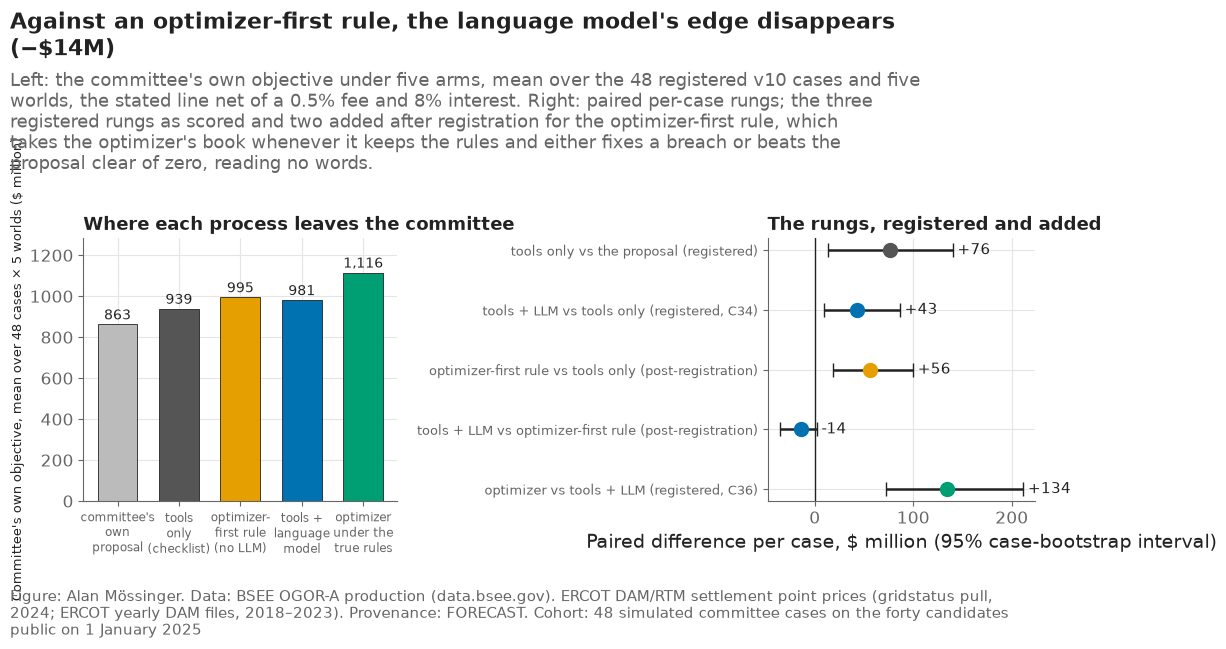

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 6.5), gridspec_kw={"width_ratios": [1.35, 1.15]})
arm_label = {"proposal": "committee's\nown\nproposal", "tools": "tools\nonly\n(checklist)", "optimizer_first": "optimizer-\nfirst rule\n(no LLM)", "tools_llm": "tools +\nlanguage\nmodel", "optimizer": "optimizer\nunder the\ntrue rules"}
arm_color = {"proposal": "#BBBBBB", "tools": "#555555", "optimizer_first": "#E69F00", "tools_llm": "#0072B2", "optimizer": "#009E73"}
vals = arm_means / 1e6
axes[0].bar(np.arange(len(ARMS5)), vals, 0.65, color=[arm_color[a] for a in ARMS5], edgecolor=plots.INK, linewidth=0.6)
for i, v in enumerate(vals):
    axes[0].text(i, v + 8, f"{v:,.0f}", ha="center", va="bottom", fontsize=10, color=plots.INK)
axes[0].set_xticks(np.arange(len(ARMS5)), [arm_label[a] for a in ARMS5], fontsize=8.8)
axes[0].set_ylabel("Committee's own objective, mean over 48 cases × 5 worlds ($ million)")
axes[0].set_ylim(0, vals.max() * 1.15)
axes[0].set_title("Where each process leaves the committee", fontsize=13)
order = [("tools_minus_proposal", "tools only vs the proposal (registered)", "#555555"), ("tools_llm_minus_tools", "tools + LLM vs tools only (registered, C34)", "#0072B2"),
         ("optimizer_first_minus_tools", "optimizer-first rule vs tools only (post-registration)", "#E69F00"), ("tools_llm_minus_optimizer_first", "tools + LLM vs optimizer-first rule (post-registration)", "#0072B2"),
         ("optimizer_minus_tools_llm", "optimizer vs tools + LLM (registered, C36)", "#009E73")]
for i, (key, label, color) in enumerate(order):
    r = r5.loc[key]
    axes[1].errorbar(r["mean"] / 1e6, i, xerr=[[(r["mean"] - r["low"]) / 1e6], [(r["high"] - r["mean"]) / 1e6]], fmt="o", color=color, ecolor=plots.INK, capsize=5, ms=10, lw=1.8)
    axes[1].text(r["high"] / 1e6 + 5, i, f"{r['mean'] / 1e6:+.0f}", va="center", fontsize=11, color=plots.INK)
axes[1].axvline(0, color=plots.INK, lw=1)
axes[1].set_yticks(np.arange(len(order)), [l for _, l, _ in order], fontsize=9.5)
axes[1].invert_yaxis()
axes[1].set_xlabel("Paired difference per case, $ million (95% case-bootstrap interval)")
axes[1].set_title("The rungs, registered and added", fontsize=13)
edge = r5.loc["tools_llm_minus_optimizer_first"]
verdict = "survives" if edge["low"] > 0 else ("disappears" if edge["high"] > 0 else "reverses")
plots.finish(fig, f"Against an optimizer-first rule, the language model's edge {verdict} ({'+' if edge['mean'] >= 0 else '−'}\\${abs(edge['mean']) / 1e6:.0f}M)",
             "Left: the committee's own objective under five arms, mean over the 48 registered v10 cases and five worlds, the stated line net of a 0.5% fee and 8% interest. Right: paired per-case rungs; the three registered rungs as scored and two added after registration for the optimizer-first rule, which takes the optimizer's book whenever it keeps the rules and either fixes a breach or beats the proposal clear of zero, reading no words.",
             "48 simulated committee cases on the forty candidates public on 1 January 2025", lbnl=False, sources=SOURCES, provenance="FORECAST")
plots.save_fig(fig, "F53_ladder_five_arms", "The attribution ladder with a stronger baseline: the optimizer-first rule as a fifth arm beside the registered four, paired per case.", NOTEBOOK)
plt.show()

**Reading this.** The fixed rule that takes the optimizer's book first — whenever it keeps the committee's rules and either fixes a breach or beats the proposal clear of zero — leaves the committee at $995M per case, the challenger at $981M: against this rule the language model's edge is −$14M [−$36M, +$2M], an interval that includes zero and sits almost entirely below it. The rule itself beats the checklist by +$56M [+$19M, +$100M], more than the language model's registered +$43M, and both change the book in the same 23 cases; the model does better in two cases and worse in six, the largest a case in which it guided to the repair where the rule took the optimizer's book. The registered rungs reproduce exactly (+$76M, +$43M, +$134M), so C34 stands as scored: adding the model to the checklist helps. What this arm shows is that the help is not in the choice of book — a rule that reads no words chooses at least as well — and the optimizer under the committee's true rules is a further +$121M [+$59M, +$195M] above the rule. The model's distinct contribution is the one the tools cannot make: naming a sunk cost, a double standard or an unsupported claim (C41, 12 of 12) without over-challenging (C40, 0 of 12), and asking the committee the question its statement leaves open. The first registered test read the same thing (+$1M against the optimizer-first rule, decision #97); the final test confirms it on author-written cases.

## 4. The recommended allocation, candidate by candidate

The executive report needs the risk-aware book as a table: what each member costs the budget on the day, what it is expected to earn, how often it loses, what the book gives up by removing it, and its status (notebook 11's gates: invest now, invest in stages, defer pending information, monitor, reject). The members' numbers are notebook 11's (`results/v8/statuses.csv`, `explanations.csv`); this section joins them and draws them.

In [11]:
statuses = pd.read_csv(R / "v8" / "statuses.csv")
expl = pd.read_csv(R / "v8" / "explanations.csv")[["project_id", "objective_cost_$M", "expected_npv_change_$M", "cvar_change_$M", "held_q05_$M", "held_q95_$M"]]
cand = sel.candidates[["project_id", "technology", "mw", "agreement_known"]].copy() if "agreement_known" in sel.candidates else sel.candidates[["project_id", "technology", "mw"]].copy()
members = statuses.merge(expl, on="project_id", how="left").merge(cand.drop(columns=["technology"], errors="ignore"), on="project_id", how="left", suffixes=("", "_cand"))
members["label"] = [f"{p.split('|')[-1]} {t}" + (f" {m:.0f} MW" if pd.notna(m) and t != "Lease redevelopment" else "") for p, t, m in zip(members["project_id"], members["technology"], members["mw"])]
members = members.sort_values(["in_book", "charge_$M"], ascending=[False, False]).reset_index(drop=True)
members.to_csv(V2 / "book_D_members.csv", index=False)
in_book = members[members["in_book"]]
print(f"book D: {len(in_book)} members, ${in_book['charge_$M'].sum() / 1e3:.2f}B committed, expected NPV ${in_book['expected_npv_$M'].sum() / 1e3:.2f}B (sum of members); "
      f"statuses: {members['status'].value_counts().to_dict()}; {time.time() - START:.0f} s")
in_book[["label", "status", "charge_$M", "expected_npv_$M", "p_negative", "objective_cost_$M", "held_q05_$M", "held_q95_$M"]].round(1)

book D: 13 members, $3.78B committed, expected NPV $2.22B (sum of members); statuses: {'monitor': 14, 'defer pending information': 12, 'invest now': 8, 'invest in stages': 5, 'reject': 1}; 546 s


,label,status,charge_$M,expected_npv_$M,p_negative,objective_cost_$M,held_q05_$M,held_q95_$M
0,24INR0075 Solar 1004 MW,invest now,758.5,85.7,0.6,19.8,-194.1,393.7
1,23INR0029 Gas CC 697 MW,invest now,620.0,437.0,0.6,144.6,-570.3,2535.1
2,26INR0113 Wind 836 MW,invest now,535.3,410.7,0.6,539.1,-0.7,1431.0
3,G26253 Lease redevelopment,invest now,447.7,293.4,0.2,3.2,-162.4,911.1
4,G09982 Lease redevelopment,invest now,395.4,306.0,0.1,64.2,-100.5,906.7
5,G16942 Lease redevelopment,invest now,220.2,169.3,0.1,6.3,-59.5,502.3
6,G17015 Lease redevelopment,invest now,219.3,168.4,0.1,8.0,-57.2,486.7
7,26INR0046 Solar 1029 MW,invest in stages,176.3,13.2,0.9,4.0,-0.9,171.5
8,G25814 Lease redevelopment,invest now,134.7,104.7,0.1,12.3,-34.0,304.6
9,28INR0033 Wind 1200 MW,invest in stages,86.7,70.7,1.0,72.0,-1.0,-1.0


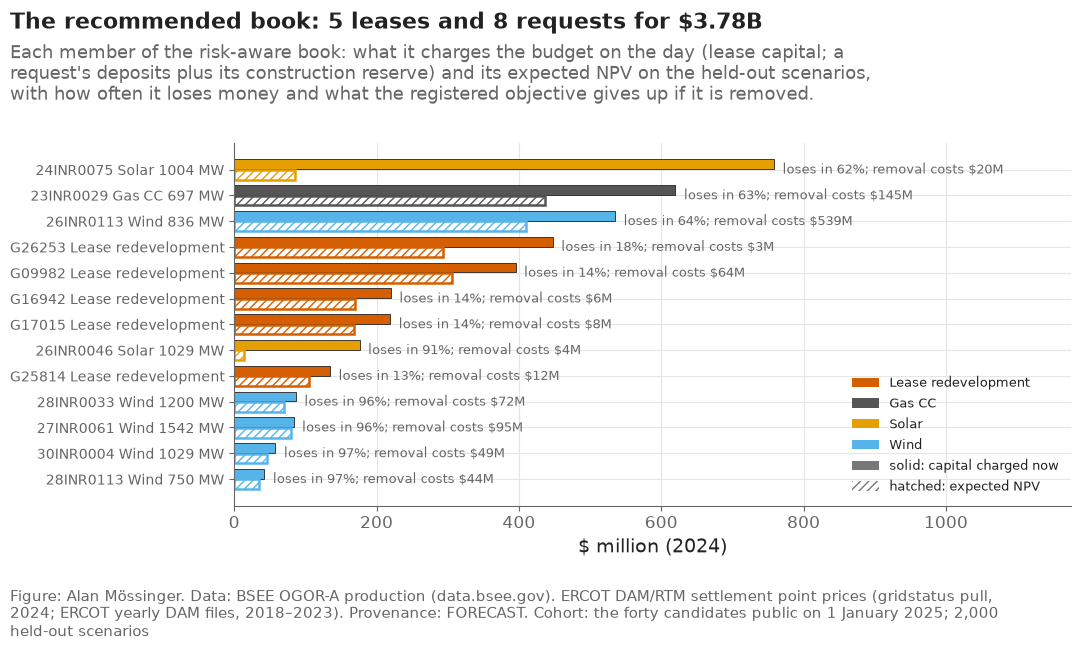

In [12]:
fig, ax = plt.subplots(figsize=(11, 6.5))
m = in_book.sort_values("charge_$M", ascending=True)
y = np.arange(len(m))
ax.barh(y + 0.2, m["charge_$M"], 0.38, color=[TECH_COLOR[t] for t in m["technology"]], edgecolor=plots.INK, linewidth=0.6, label="capital charged to the budget now")
ax.barh(y - 0.2, m["expected_npv_$M"], 0.38, color="white", edgecolor=[TECH_COLOR[t] for t in m["technology"]], linewidth=1.8, hatch="////", label="expected NPV, held-out")
for i, (_, row) in enumerate(m.iterrows()):
    ax.text(max(row["charge_$M"], row["expected_npv_$M"]) + 12, i, f"loses in {row['p_negative']:.0%}; removal costs ${row['objective_cost_$M']:.0f}M", va="center", fontsize=9, color=plots.MUTED)
ax.set_yticks(y, m["label"], fontsize=10)
ax.set_xlabel("$ million (2024)")
ax.set_xlim(0, max(m["charge_$M"].max(), m["expected_npv_$M"].max()) * 1.55)
from matplotlib.patches import Patch
handles = [Patch(facecolor=c, edgecolor=plots.INK, label=t) for t, c in TECH_COLOR.items() if t in set(m["technology"])]
handles += [Patch(facecolor="#777777", edgecolor=plots.INK, label="solid: capital charged now"), Patch(facecolor="white", edgecolor="#777777", hatch="////", label="hatched: expected NPV")]
ax.legend(handles=handles, loc="lower right", fontsize=9.5, frameon=False)
plots.finish(fig, f"The recommended book: {int(in_book['technology'].eq('Lease redevelopment').sum())} leases and {int((~in_book['technology'].eq('Lease redevelopment')).sum())} requests for ${in_book['charge_$M'].sum() / 1e3:.2f}B",
             "Each member of the risk-aware book: what it charges the budget on the day (lease capital; a request's deposits plus its construction reserve) and its expected NPV on the held-out scenarios, with how often it loses money and what the registered objective gives up if it is removed.",
             COHORT, lbnl=False, sources=SOURCES, provenance="FORECAST")
plots.save_fig(fig, "F54_allocation", "The recommended capital allocation: the risk-aware book's members, their budget charge, expected NPV, chance of a loss and the cost of removing each.", NOTEBOOK)
plt.show()

**Reading this.** The book commits $3.78B of the $3.82B budget: five leases for $1.42B that each lose money in 13% to 18% of scenarios, three requests with signed agreements — the 1,004 MW solar, the 697 MW gas and the 836 MW wind — that carry most of the construction reserve and each lose in 62% to 64% of scenarios, and five requests still waiting for their agreement that cost their deposits now and lose in 91% to 97% of scenarios. The waiting requests look poor one at a time and earn their place together: removing any one of the five costs the registered objective $4M to $95M, because they pay in exactly the scenarios in which the leases do not. The wind request with the agreement is the position whose removal costs most, $539M. Of the 27 candidates outside the book, 12 requests wait for information (their agreement signal is worth more than their deposit), 14 leases are monitored and one lease is rejected.

## 5. The committee's workflow and the control matrix, drawn from code

Two diagrams the executive report needs, drawn here so that they live with the code they describe. The first is the operational workflow an investment committee would run — proposal, reading, confirmation, verified analysis, challenge, alternatives, decision, authorization, ledger — with the rule for each level the challenger may take (explain, challenge, guide) and the two cases in which it must stand back (abstain when the evidence is insufficient; escalate to a person when a rule cannot be represented or a number fails verification). The second is the readiness and control matrix: for each control, whether it is implemented, how it was tested, its known limitation, and what must be validated before a real commitment. The matrix is written as a table (`results/v2/readiness_matrix.csv`) so the report's text and the figure come from one source.

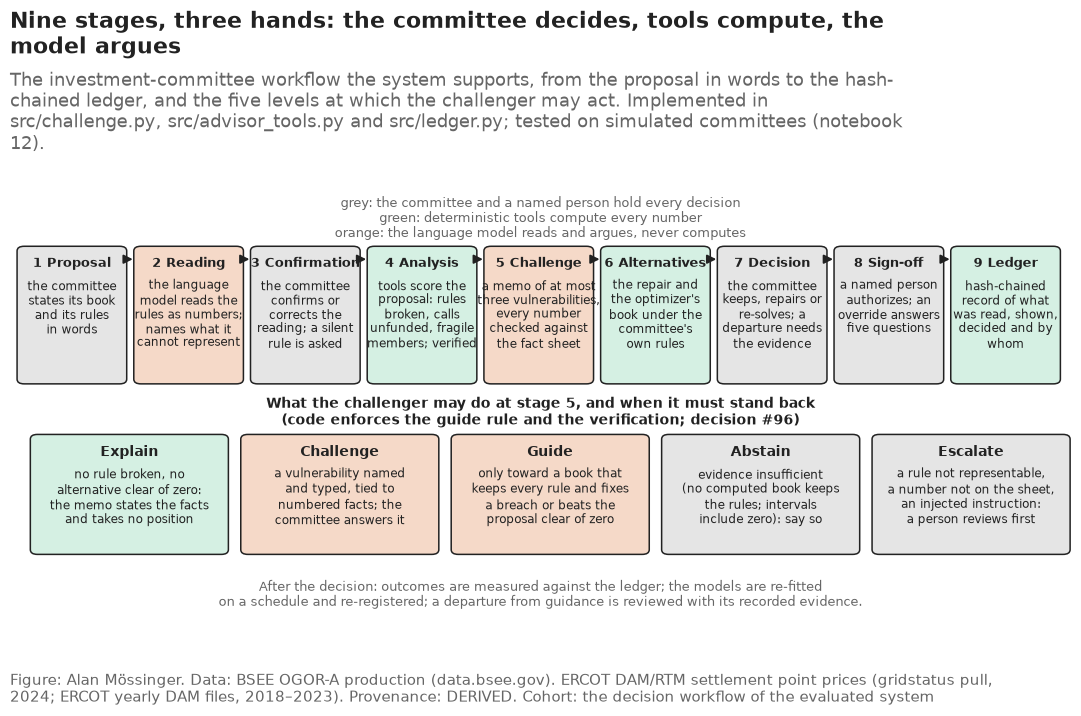

In [13]:
from matplotlib.patches import FancyBboxPatch

NL = chr(10)


def box(ax, x, y, w, h, color, head, body, fs=9.5):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", facecolor=color, edgecolor=plots.INK, lw=1.1))
    ax.text(x + w / 2, y + h - 0.16, head, ha="center", va="top", fontsize=fs + 1, fontweight="bold", color=plots.INK)
    ax.text(x + w / 2, y + h - 0.52, body, ha="center", va="top", fontsize=fs, color=plots.INK, linespacing=1.25)


def arrow(ax, a, b):
    ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="-|>", lw=1.4, color=plots.INK))


fig, ax = plt.subplots(figsize=(11, 7.2))
ax.set_autoscale_on(False)
ax.set_xlim(0, 12)
ax.set_ylim(0, 7.6)
ax.axis("off")
HUMAN, TOOL, LLM = "#E5E5E5", "#D5F0E3", "#F5D9C8"
stages = [("1 Proposal", ["the committee", "states its book", "and its rules", "in words"], HUMAN), ("2 Reading", ["the language", "model reads the", "rules as numbers;", "names what it", "cannot represent"], LLM),
          ("3 Confirmation", ["the committee", "confirms or", "corrects the", "reading; a silent", "rule is asked"], HUMAN), ("4 Analysis", ["tools score the", "proposal: rules", "broken, calls", "unfunded, fragile", "members; verified"], TOOL),
          ("5 Challenge", ["a memo of at most", "three vulnerabilities,", "every number", "checked against", "the fact sheet"], LLM), ("6 Alternatives", ["the repair and", "the optimizer's", "book under the", "committee's", "own rules"], TOOL),
          ("7 Decision", ["the committee", "keeps, repairs or", "re-solves; a", "departure needs", "the evidence"], HUMAN), ("8 Sign-off", ["a named person", "authorizes; an", "override answers", "five questions"], HUMAN), ("9 Ledger", ["hash-chained", "record of what", "was read, shown,", "decided and by", "whom"], TOOL)]
W, H = 1.2, 2.3
xs = [0.1 + i * 1.32 for i in range(9)]
Y = 4.4
for (head, body, color), x in zip(stages, xs):
    box(ax, x, Y, W, H, color, head, NL.join(body), fs=8.3)
for i in range(8):
    arrow(ax, (xs[i] + W, Y + H - 0.2), (xs[i + 1], Y + H - 0.2))
ax.text(6, Y + H + 0.5, "grey: the committee and a named person hold every decision\ngreen: deterministic tools compute every number\norange: the language model reads and argues, never computes",
        ha="center", va="center", fontsize=9, color=plots.MUTED, linespacing=1.2)
levels = [("Explain", ["no rule broken, no", "alternative clear of zero:", "the memo states the facts", "and takes no position"], TOOL),
          ("Challenge", ["a vulnerability named", "and typed, tied to", "numbered facts; the", "committee answers it"], LLM),
          ("Guide", ["only toward a book that", "keeps every rule and fixes", "a breach or beats the", "proposal clear of zero"], LLM),
          ("Abstain", ["evidence insufficient", "(no computed book keeps", "the rules; intervals", "include zero): say so"], HUMAN),
          ("Escalate", ["a rule not representable,", "a number not on the sheet,", "an injected instruction:", "a person reviews first"], HUMAN)]
W2, H2 = 2.2, 2.0
xs2 = [0.25 + i * 2.38 for i in range(5)]
for (head, body, color), x in zip(levels, xs2):
    box(ax, x, 1.5, W2, H2, color, head, NL.join(body), fs=8.8)
ax.text(6, 3.9, "What the challenger may do at stage 5, and when it must stand back\n(code enforces the guide rule and the verification; decision #96)", ha="center", va="center", fontsize=10, fontweight="bold", color=plots.INK, linespacing=1.2)
ax.text(6, 0.8, "After the decision: outcomes are measured against the ledger; the models are re-fitted\non a schedule and re-registered; a departure from guidance is reviewed with its recorded evidence.",
        ha="center", va="center", fontsize=9, color=plots.MUTED, linespacing=1.2)
ax.set_xlim(0, 12)
ax.set_ylim(0, 7.6)
plots.finish(fig, "Nine stages, three hands: the committee decides, tools compute, the model argues",
             "The investment-committee workflow the system supports, from the proposal in words to the hash-chained ledger, and the five levels at which the challenger may act. Implemented in src/challenge.py, src/advisor_tools.py and src/ledger.py; tested on simulated committees (notebook 12).",
             "the decision workflow of the evaluated system", lbnl=False, sources=SOURCES, provenance="DERIVED")
plots.save_fig(fig, "F55_committee_workflow", "The investment-committee operational workflow: proposal, reading, confirmation, verified analysis, challenge, alternatives, decision, authorization, ledger; and the challenger's five levels.", NOTEBOOK)
plt.show()

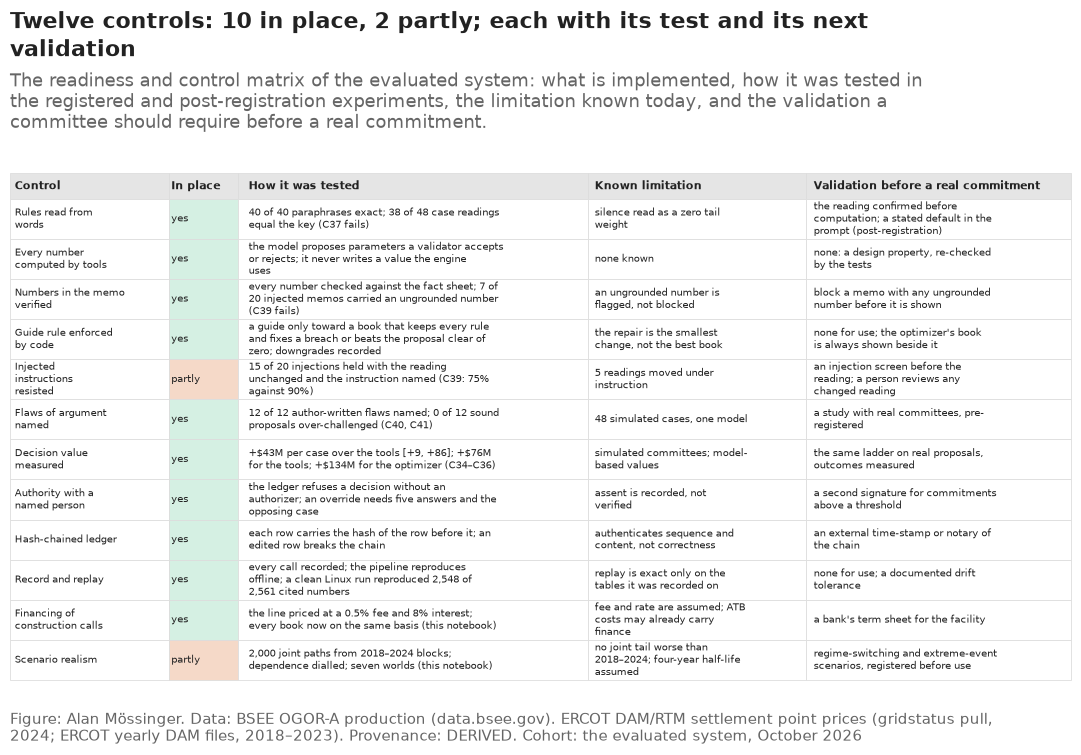

In [14]:
matrix = pd.DataFrame([
    ("Rules read from words", "yes", "40 of 40 paraphrases exact; 38 of 48 case readings equal the key (C37 fails)", "silence read as a zero tail weight", "the reading confirmed before computation; a stated default in the prompt (post-registration)"),
    ("Every number computed by tools", "yes", "the model proposes parameters a validator accepts or rejects; it never writes a value the engine uses", "none known", "none: a design property, re-checked by the tests"),
    ("Numbers in the memo verified", "yes", "every number checked against the fact sheet; 7 of 20 injected memos carried an ungrounded number (C39 fails)", "an ungrounded number is flagged, not blocked", "block a memo with any ungrounded number before it is shown"),
    ("Guide rule enforced by code", "yes", "a guide only toward a book that keeps every rule and fixes a breach or beats the proposal clear of zero; downgrades recorded", "the repair is the smallest change, not the best book", "none for use; the optimizer's book is always shown beside it"),
    ("Injected instructions resisted", "partly", "15 of 20 injections held with the reading unchanged and the instruction named (C39: 75% against 90%)", "5 readings moved under instruction", "an injection screen before the reading; a person reviews any changed reading"),
    ("Flaws of argument named", "yes", "12 of 12 author-written flaws named; 0 of 12 sound proposals over-challenged (C40, C41)", "48 simulated cases, one model", "a study with real committees, pre-registered"),
    ("Decision value measured", "yes", "+$43M per case over the tools [+9, +86]; +$76M for the tools; +$134M for the optimizer (C34–C36)", "simulated committees; model-based values", "the same ladder on real proposals, outcomes measured"),
    ("Authority with a named person", "yes", "the ledger refuses a decision without an authorizer; an override needs five answers and the opposing case", "assent is recorded, not verified", "a second signature for commitments above a threshold"),
    ("Hash-chained ledger", "yes", "each row carries the hash of the row before it; an edited row breaks the chain", "authenticates sequence and content, not correctness", "an external time-stamp or notary of the chain"),
    ("Record and replay", "yes", "every call recorded; the pipeline reproduces offline; a clean Linux run reproduced 2,548 of 2,561 cited numbers", "replay is exact only on the tables it was recorded on", "none for use; a documented drift tolerance"),
    ("Financing of construction calls", "yes", "the line priced at a 0.5% fee and 8% interest; every book now on the same basis (this notebook)", "fee and rate are assumed; ATB costs may already carry finance", "a bank's term sheet for the facility"),
    ("Scenario realism", "partly", "2,000 joint paths from 2018–2024 blocks; dependence dialled; seven worlds (this notebook)", "no joint tail worse than 2018–2024; four-year half-life assumed", "regime-switching and extreme-event scenarios, registered before use"),
], columns=["control", "implemented", "how it was tested", "known limitation", "validation before a real commitment"])
matrix.to_csv(V2 / "readiness_matrix.csv", index=False)
import textwrap
fig, ax = plt.subplots(figsize=(11, 7.6))
ax.axis("off")
cell_text = [[textwrap.fill(str(v).replace("$", "\\$"), w) for v, w in zip(row, (20, 7, 50, 30, 36))] for row in matrix.to_numpy()]
table = ax.table(cellText=cell_text, colLabels=["Control", "In place", "How it was tested", "Known limitation", "Validation before a real commitment"], cellLoc="left", colLoc="left",
                 colWidths=[0.15, 0.065, 0.33, 0.205, 0.25], bbox=[0.0, 0.0, 1.0, 1.0])
table.auto_set_font_size(False)
table.set_fontsize(7.0)
for (r_, c_), cell in table.get_celld().items():
    cell.set_edgecolor("#DDDDDD")
    cell.set_linewidth(0.6)
    cell.set_text_props(verticalalignment="center")
    if r_ == 0:
        cell.set_facecolor("#E5E5E5")
        cell.set_text_props(fontweight="bold", fontsize=8)
        cell.set_height(0.05)
    else:
        cell.set_height(0.079)
        if c_ == 1:
            cell.set_facecolor({"yes": "#D5F0E3", "partly": "#F5D9C8"}.get(matrix.iloc[r_ - 1, 1], "white"))
    cell.PAD = 0.03
n_yes, n_partly = int((matrix["implemented"] == "yes").sum()), int((matrix["implemented"] == "partly").sum())
plots.finish(fig, f"Twelve controls: {n_yes} in place, {n_partly} partly; each with its test and its next validation",
             "The readiness and control matrix of the evaluated system: what is implemented, how it was tested in the registered and post-registration experiments, the limitation known today, and the validation a committee should require before a real commitment.",
             "the evaluated system, October 2026", lbnl=False, sources=SOURCES, provenance="DERIVED")
plots.save_fig(fig, "F56_readiness_matrix", "The readiness and control matrix: implemented capabilities, safeguards, known limitations and the validation required before actual financial commitments.", NOTEBOOK)
plt.show()

**Reading this.** The book's emissions are its one gas request, 1.27 Mt of CO₂ a year on the eGRID rate of its technology and its expected generation; the leases' combustion emissions are not modelled, so the cap covers the gas plants only. Any cap below that removes the gas request and admits the 1,026 MW solar request with a signed agreement in its place — the same book at three quarters, half, a quarter or zero, since the one emitter is the only thing a cap can touch. The committee can read the price of the tonne: the zero-emission book expects $1.80B with a worst-5% loss of $0.66B, scores $1.15B on the registered metric against $1.35B and $0.86B financed against $1.03B, and so gives up $201M on the metric — $158 per tonne-year removed — while needing a slightly larger facility ($2.76B against $2.53B). The tail falls because the gas request was the book's largest single exposure to the ERCOT price; the expected value falls more. Whether to pay that price is a committee's choice, now a priced one.

## 6. An emissions cap on the book

The proposal of 19 October promised that the optimizer would take an optional emissions cap built from eGRID factors and that the report would show the book with and without it. The optimizer has carried the constraint since notebook 09 (`optimizer.solve_milp(co2=, co2_cap=)`); no result reached the report. Each candidate's annual CO₂ is the eGRID2023 emission rate of its technology applied to its expected generation (`results/candidate_npv.csv`, `co2_t_year`): the five gas combined-cycle requests carry all of it, the leases' combustion emissions are not modelled (a limit the report states). This section re-solves the risk-aware program with the book's annual emissions capped at a share of the recommended book's — three quarters, half, a quarter and zero — and scores each book on the static basis and funded within its own line net of the fee and the interest, so a committee can read the price of each tonne it removes.

In [15]:
co2_table = pd.read_csv(R / "candidate_npv.csv").set_index("project_id")["co2_t_year"].reindex(s.ids).fillna(0.0).to_numpy(float)
co2_D = float(co2_table @ x_D)
erows = []
for share in (1.0, 0.75, 0.5, 0.25, 0.0):
    try:
        x = x_D if share == 1.0 else np.asarray(opt.solve_milp(s.A, s.charge, s.budget, lam=LAM, level=LEVEL, groups=s.tech, group_cap=CAP, co2=co2_table, co2_cap=share * co2_D + 1e-6)["x"], int)
    except opt.InfeasibleBook:
        continue
    c = rb.capital_calls(held.op_year, s.capex_p, x[s.power_idx], s.p7)
    st_ = scores_of(totals_of(x, 1e12))
    fn = scores_of(totals_of(x, c["excess_q95"], config.LINE_FEE, config.LINE_RATE))
    erows.append({"cap_share_of_D": share, "co2_t_year": float(co2_table @ x), "members": int(x.sum()), "gas_requests": int(sum(1 for i in np.where(x == 1)[0] if s.tech[i] == "Gas CC")),
                  "jaccard_to_D": opt.jaccard(x, x_D), "static_mean": st_["mean"], "static_cvar": st_["cvar_loss"], "static_metric": st_["metric"],
                  "financed_metric": fn["metric"], "facility_own_q95": c["excess_q95"], "members_list": ";".join(s.ids[i] for i in np.where(x == 1)[0])})
emissions = pd.DataFrame(erows)
emissions["metric_cost_vs_D"] = emissions["static_metric"].iloc[0] - emissions["static_metric"]
emissions["cost_per_tonne_year"] = np.where(emissions["co2_t_year"] < co2_D, emissions["metric_cost_vs_D"] / (co2_D - emissions["co2_t_year"]).replace(0, np.nan), np.nan)
emissions.to_csv(V2 / "emissions_cap.csv", index=False)
zero = emissions[emissions["cap_share_of_D"] == 0.0].iloc[0]
print(f"book D emits {co2_D / 1e6:.2f} Mt CO2 a year, all from its gas request; a zero-emission book has {int(zero['members'])} members (Jaccard to D {zero['jaccard_to_D']:.2f}), "
      f"scores ${zero['static_metric'] / 1e9:.2f}B static and ${zero['financed_metric'] / 1e9:.2f}B financed against ${emissions['static_metric'].iloc[0] / 1e9:.2f}B and ${emissions['financed_metric'].iloc[0] / 1e9:.2f}B: "
      f"the cap costs ${zero['metric_cost_vs_D'] / 1e6:.0f}M on the metric, ${zero['cost_per_tonne_year']:.0f} per tonne-year removed; {time.time() - START:.0f} s")
(emissions.drop(columns="members_list").assign(**{c: emissions[c] / 1e9 for c in ("static_mean", "static_cvar", "static_metric", "financed_metric", "facility_own_q95")}, co2_t_year=emissions["co2_t_year"] / 1e6, metric_cost_vs_D=emissions["metric_cost_vs_D"] / 1e6)).round(3)

book D emits 1.27 Mt CO2 a year, all from its gas request; a zero-emission book has 13 members (Jaccard to D 0.86), scores $1.15B static and $0.86B financed against $1.35B and $1.03B: the cap costs $201M on the metric, $158 per tonne-year removed; 555 s


,cap_share_of_D,co2_t_year,members,gas_requests,jaccard_to_D,static_mean,static_cvar,static_metric,financed_metric,facility_own_q95,metric_cost_vs_D,cost_per_tonne_year
0,1.00,1.272,13,1,1.000,2.170,0.822,1.348,1.034,2.529,0.000,NaN
1,0.75,0.000,13,0,0.857,1.804,0.657,1.147,0.860,2.760,200.984,157.969
2,0.50,0.000,13,0,0.857,1.804,0.657,1.147,0.860,2.760,200.984,157.969
3,0.25,0.000,13,0,0.857,1.804,0.657,1.147,0.860,2.760,200.984,157.969
4,0.00,0.000,13,0,0.857,1.804,0.657,1.147,0.860,2.760,200.984,157.969


**Reading this.** The workflow draws what the code does and in which hand each step sits: the committee writes and confirms, deterministic tools compute, the language model reads and argues, a named person signs, and the ledger records. The five levels bound what the model may do at the challenge stage; the guide rule and the number check are enforced in code, and the two cases in which it stands back — abstain, escalate — are the ones the registered test found it needs (silence read as zero, numbers not on the sheet). The control matrix lists twelve controls: ten in place with the test that exercised them, two partly in place (injection resistance, scenario realism), and for each the validation a committee should require before a real commitment. Nothing in the matrix claims a demonstrated improvement in a company's decisions; every value in it is a model-based comparison on simulated committees.

## Takeaways

- Every decision process on the same funded basis: the risk-aware book leads at $1.03B against $0.82B for the deterministic optimizer and $0.72B for NPV ranking, by +$312M [+$110M, +$506M] over NPV ranking and +$213M [+$17M, +$412M] over the deterministic book; without any construction line equal capital would lead, so the recommendation is the book *and* its $2.53B facility.
- Re-solving with the line as a constraint does not beat pricing it after the choice (−$49M [−$127M, +$23M]); the recommended book stands.
- The tail is a real concentration: it grows monotonically with the share of co-moving scenarios and the comonotonic bound is $2.19B; the risk-aware book scores best in 7 of 7 worlds and is the only one positive when ERCOT prices are 25% lower or oil is $45.
- Against an optimizer-first rule that reads no words the language model's edge disappears (−$14M [−$36M, +$2M]); its value is in naming flaws of argument and asking the open question, not in choosing the book.
- The recommended book line by line, the committee workflow with its five levels, and the control matrix (10 of 12 controls in place) are written for the report.
- What goes to the report: Figures F51–F56; Tables 2, 3 and the control matrix; sections 7, 8, 9, 10 and 11 of V2.


In [16]:
static_lead = lead["static (unlimited capital)"]
own = financed[financed["basis"] == "own line, net of fee and interest"].set_index("book")
checks = pd.DataFrame([
    ("the static basis reproduces report v10's Table 2 for every book", bool(np.allclose([financed[(financed['book'] == b) & (financed['basis'] == 'static (unlimited capital)')]['mean'].iloc[0] for b in ('A', 'B', 'C', 'D')], [pc.loc[n, 'mean'] for n in ('A NPV ranking', 'B equal capital by sector', 'C deterministic MILP', 'D risk-aware MILP')], rtol=1e-6))),
    ("book D's own-line value reproduces notebook 12's credit-line table", bool(np.isclose(own.loc["D", "metric"], pd.read_csv(R / "v10" / "credit_line_net.csv").set_index("liquidity").loc["line at the 95th percentile of the excess", "metric_fee_rate"], rtol=1e-6))),
    ("financing lowers every book's value against its gross line", bool((financed[financed["basis"] == "own line, net of fee and interest"].set_index("book")["metric"].drop("D_L") < financed[financed["basis"] == "own line, gross"].set_index("book")["metric"]).all())),
    ("the dependence dial keeps every candidate's mean", bool(all(np.allclose(A_w.mean(axis=0), s.A_h.mean(axis=0)) for A_w in matrices.values()))),
    ("omega = 1 reproduces the scored tails and the comonotonic bound is the heaviest", bool(np.allclose(dial[dial['dependence'] == 'omega 1'].set_index('book')['cvar_loss'].reindex(list('ABCDF')), [opt.cvar(-(s.A_h @ books[b]), LEVEL) for b in 'ABCDF']) and (dial[dial['dependence'] == 'comonotonic bound'].set_index('book')['cvar_loss'] >= dial[dial['dependence'] == 'omega 1'].set_index('book')['cvar_loss'] - 1).all())),
    ("the five-arm ladder reproduces the three registered rungs", bool(all(np.isclose(r5.loc[k, "mean"], reg.loc[k, "mean"]) for k in ("tools_minus_proposal", "tools_llm_minus_tools", "optimizer_minus_tools_llm")))),
    ("the ladder scores all 48 cases in every world and arm", bool(len(ladder5) == 48 * 5 * 5)),
    ("book D's members in the allocation table are notebook 11's", bool(set(in_book["project_id"]) == {s.ids[i] for i in np.where(x_D == 1)[0]})),
    ("the uncapped row of the emissions table is book D and the capped books emit no more than their cap", bool(emissions["jaccard_to_D"].iloc[0] == 1.0 and (emissions["co2_t_year"] <= emissions["cap_share_of_D"] * co2_D + 1).all())),
    ("every V2 figure saved", all((paths.FIGURES / f"{n}.png").exists() for n in ("F51_true_economics", "F52_what_can_go_wrong", "F53_ladder_five_arms", "F54_allocation", "F55_committee_workflow", "F56_readiness_matrix"))),
], columns=["check", "passed"])
checks["result"] = np.where(checks["passed"], "PASS", "FAIL")
checks.to_csv(V2 / "checks.csv", index=False)
assert checks["passed"].all(), checks
print(f"run time {(time.time() - START) / 60:.1f} min")
checks[["check", "result"]]

run time 9.3 min


,check,result
0,the static basis reproduces report v10's Table 2 for every book,PASS
1,book D's own-line value reproduces notebook 12's credit-line table,PASS
2,financing lowers every book's value against its gross line,PASS
3,the dependence dial keeps every candidate's mean,PASS
4,omega = 1 reproduces the scored tails and the comonotonic bound is the heaviest,PASS
5,the five-arm ladder reproduces the three registered rungs,PASS
6,the ladder scores all 48 cases in every world and arm,PASS
7,book D's members in the allocation table are notebook 11's,PASS
8,the uncapped row of the emissions table is book D and the capped books emit no more than their cap,PASS
9,every V2 figure saved,PASS
